## Pediatric Wrist Fracture Detection and Classification

This notebook evaluates a YOLOv8 Nano model trained to detect visible fractures in pediatric wrist X-ray images and explores its use for image-level fracture classification, with a particular focus on hidden fractures.

## Experimental approach

Initial experiments with custom CNN architectures and a pretrained ResNet model did not produce satisfactory classification results. We therefore explored an object-detection approach using YOLOv8 Nano.

The dataset was prepared so that patients with hidden fractures were excluded from training and validation. All images belonging to those patients were assigned to the test set to prevent patient-level data leakage.

The YOLO model was trained to detect visible fractures. For image-level classification, we used the following decision rule:

- If the model detects at least one bounding box with a confidence score of 0.05 or higher, the image is classified as containing a fracture.
- Otherwise, the image is classified as containing no fracture.

The main objective was to investigate whether this approach could identify hidden fractures that were not represented as positive examples during training.

### 1. Install and Import Libraries

In [7]:
!pip install ultralytics -q

In [8]:
import os
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

from ultralytics import YOLO
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### 2. Configure Paths and Parameters

Update these paths if you run the notebook in a different Kaggle environment. The paths below correspond to the Kaggle dataset and model locations used in the original experiment.

In [ ]:
DATASET_DIR = (
    "..." # dataset from previous notebook
)
TEST_CSV_PATH = (
    ".../test_split.csv"
)
TRAINED_MODEL_PATH = (
    "..." # load trained model
)

DATA_YAML_PATH = "/kaggle/working/data_yaml.yaml"
TEST_IMAGE_DIR = os.path.join(DATASET_DIR, "images", "test")

IMAGE_SIZE = 640
BATCH_SIZE = 16
CONFIDENCE_THRESHOLD = 0.05
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

### 3. Create the YOLO Configuration File
The dataset configuration specifies the training, validation, and test image directories. The task contains a single detection class: fracture (class 0).

In [10]:
data = {
    "path": DATASET_DIR,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": ["fracture"]
}

with open(DATA_YAML_PATH, "w", encoding="utf-8") as file:
    yaml.dump(data, file, sort_keys=False)

print(f"YOLO dataset configuration saved to: {DATA_YAML_PATH}")

YOLO dataset configuration saved to: /kaggle/working/data_yaml.yaml


### 4. Train the YOLOv8 Nano Model

The model was initialized with pretrained YOLOv8 Nano weights and trained for 30 epochs using an image size of 640 and a batch size of 16.

**Note**: Model training and evaluation were performed in separate Kaggle sessions. The trained weights were saved and loaded later for evaluation. Therefore, the training output may not be available in the saved notebook version. The training-results plot from the original experiment can be added below if retained as a separate image.

In [ ]:
# Initialize YOLOv8 Nano with pretrained weights
model = YOLO("yolov8n.pt")

# Train the model
train_results = model.train(
    data=DATA_YAML_PATH,
    epochs=30,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE
)

### 5. Evaluate Object Detection on the Test Set

Load the previously trained model and evaluate its object-detection performance on the test split.

The main detection metrics reported are:

- mAP@50
- mAP@50-95

#### Loading the Trained Model

The YOLOv8 model was trained in a previous session and saved for further use. In this notebook, we load the trained weights and continue with model evaluation.

The figure below shows the training and validation metrics recorded during the training process.

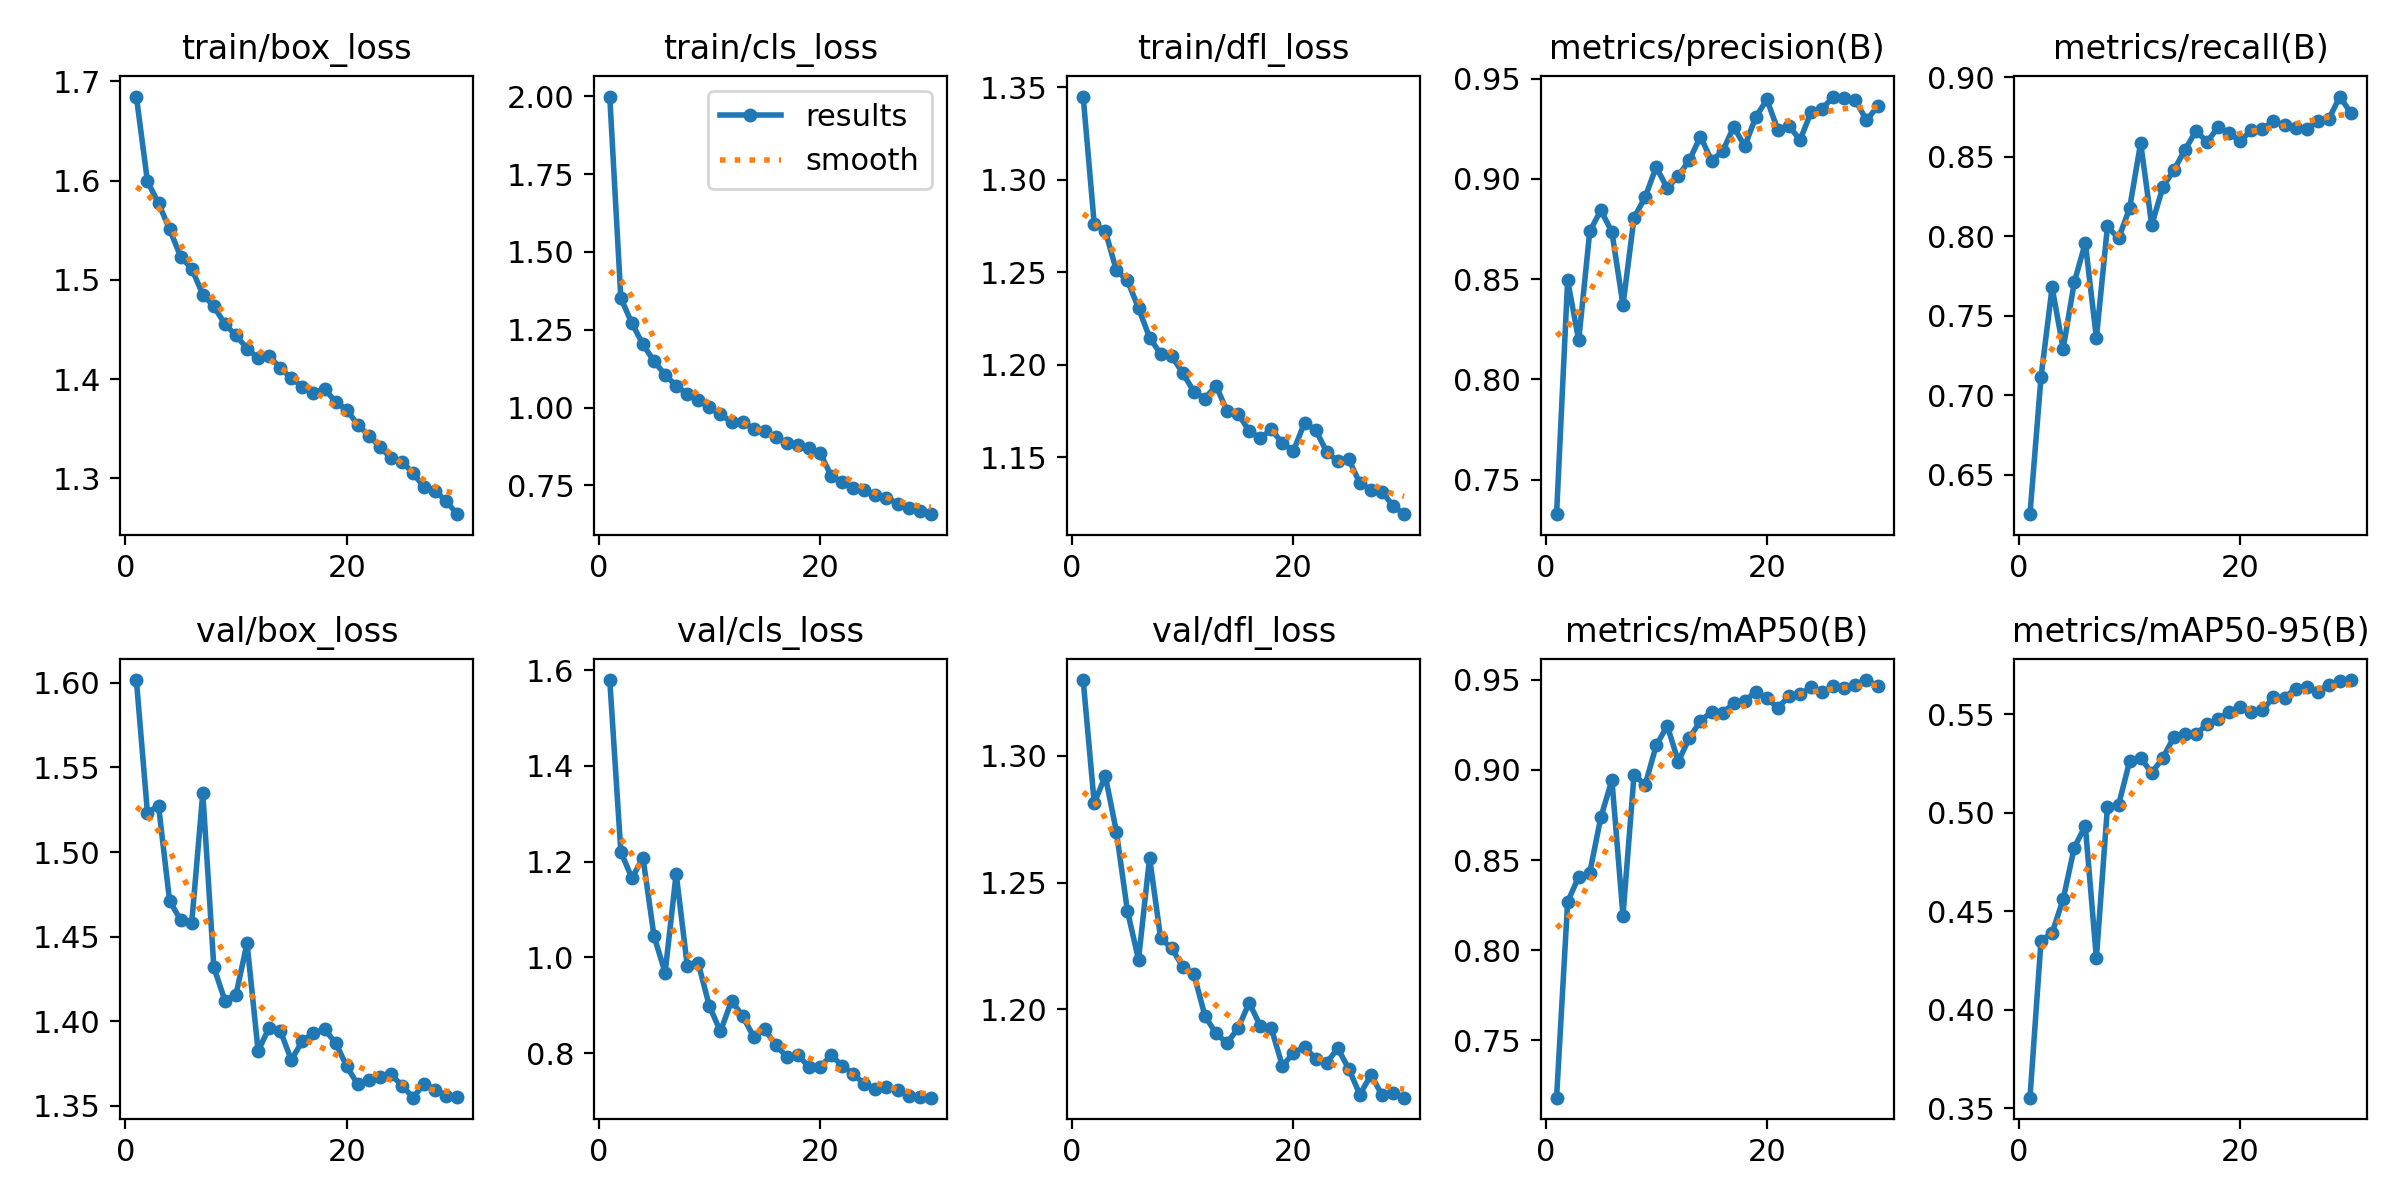

In [ ]:
trained_yolo = YOLO(TRAINED_MODEL_PATH)

test_metrics = trained_yolo.val(
    data=DATA_YAML_PATH,
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE
)

print("Object Detection Results on the Test Set")
print("----------------------------------------")
print(f"mAP@50:    {test_metrics.box.map50:.4f}")
print(f"mAP@50-95: {test_metrics.box.map:.4f}")

```Results saved to /kaggle/working/runs/detect/val

Object Detection Results on the Test Set
----------------------------------------
mAP@50:    0.8295
mAP@50-95: 0.4715```

### 6. Visualize Correctly Detected Hidden Fractures

The following function selects five hidden-fracture images that the model classified as positive. For each image, it displays the full X-ray with the predicted bounding box and a zoomed-in view of the detected region.

The same random seed is used to make the selected examples reproducible.

In [12]:
def visualize_hidden_fractures(model, results_df):
    """Display five correctly identified hidden-fracture examples."""

    successful_hidden = results_df[
                                        (results_df["is_hidden"] == 1)
                                        & (results_df["yolo_pred_class"] == 1)
                                    ]

    num_detected = len(successful_hidden)
    print(
            f"Displaying up to five correctly identified hidden fractures "
            f"(out of {num_detected} detected cases)."
        )

    if num_detected == 0:
        print("No hidden fractures were detected.")
        return

    sample_df = successful_hidden.sample(
                                            n=min(5, num_detected),
                                            random_state=RANDOM_SEED
                                        )

    fig, axes = plt.subplots(
                                len(sample_df), 2,
                                figsize=(12, 5 * len(sample_df)),
                                squeeze=False
                            )

    for i, (_, row) in enumerate(sample_df.iterrows()):
        file_stem = row["filestem"]
        image_path = os.path.join(TEST_IMAGE_DIR, f"{file_stem}.png")

        prediction = model(
                            image_path,
                            conf=CONFIDENCE_THRESHOLD,
                            verbose=False
                        )[0]

        image = cv2.imread(image_path)

        if image is None:
            print(f"Could not load image: {image_path}")
            axes[i, 0].axis("off")
            axes[i, 1].axis("off")
            continue

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        boxes = prediction.boxes

        if len(boxes) == 0:
            print(f"No bounding box found for image: {file_stem}")
            axes[i, 0].axis("off")
            axes[i, 1].axis("off")
            continue

        best_box_idx = int(np.argmax(boxes.conf.cpu().numpy()))
        x1, y1, x2, y2 = (
                            boxes.xyxy[best_box_idx]
                            .cpu()
                            .numpy()
                            .astype(int)
                        )
        confidence = boxes.conf[best_box_idx].cpu().item()

        # Display the full image with the predicted bounding box
        image_with_box = image_rgb.copy()
        cv2.rectangle(
                        image_with_box,
                        (x1, y1),
                        (x2, y2),
                        (255, 0, 0),
                        3
                    )

        axes[i, 0].imshow(image_with_box)
        axes[i, 0].set_title(f"Full X-ray (ID: {file_stem})")
        axes[i, 0].axis("off")

        # Crop the detected region with additional padding
        height, width, _ = image_rgb.shape
        padding = 20

        crop_y1 = max(0, y1 - padding)
        crop_y2 = min(height, y2 + padding)
        crop_x1 = max(0, x1 - padding)
        crop_x2 = min(width, x2 + padding)

        cropped_region = image_rgb[crop_y1:crop_y2, crop_x1:crop_x2]

        axes[i, 1].imshow(cropped_region)
        axes[i, 1].set_title(
                                f"Detected Region (Confidence: {confidence:.2f})"
                            )
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.savefig(
                    "hidden_fracture_examples.png",
                    dpi=300,
                    bbox_inches="tight"
                )
    plt.show()

### 7. Image-Level Classification Evaluation

Although YOLO is an object-detection model, its predictions can also be used to classify an entire image.

For the ground-truth labels, the presence of an AO classification is used to indicate that a fracture exists:
- ao_classification is available: fracture (1)
- ao_classification is missing: no fracture (0)
A test image is classified as positive if YOLO detects at least one bounding box at the selected confidence threshold.

The evaluation includes:
1. Overall image-level accuracy and classification report.
2. A separate analysis of the 773 hidden-fracture images.
3. A confusion matrix for the complete test set.
4. A visualization of correctly detected hidden fractures.

In [13]:
def evaluate_image_classification(model_path, test_csv_path):
    # Load the trained model and test metadata
    model = YOLO(model_path)
    results_df = pd.read_csv(test_csv_path)

    # Create binary ground-truth labels from AO classification
    results_df["ground_truth"] = (
                                    results_df["ao_classification"].notna().astype(int)
                                )

    predictions = []

    print("Running YOLO inference on the test set...")

    # Generate one image-level prediction for each test image
    for _, row in results_df.iterrows():
        file_stem = row["filestem"]
        image_path = os.path.join(TEST_IMAGE_DIR, f"{file_stem}.png")

        prediction = model(
                                image_path,
                                conf=CONFIDENCE_THRESHOLD,
                                verbose=False
                            )[0]

        # At least one detected bounding box means fracture is present
        predictions.append(int(len(prediction.boxes) > 0))

    results_df["yolo_pred_class"] = predictions

    # Evaluate the complete test set
    accuracy = accuracy_score(
                                results_df["ground_truth"],
                                results_df["yolo_pred_class"]
                            )

    print("\nImage-Level Classification Results")
    print("----------------------------------")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print("\nClassification Report:")
    print(
        classification_report(
                                results_df["ground_truth"],
                                results_df["yolo_pred_class"],
                                labels=[0, 1],
                                target_names=["No fracture", "Fracture"],
                                zero_division=0
                            )
    )

    # Evaluate hidden-fracture cases separately
    hidden_df = results_df[results_df["is_hidden"] == 1].copy()

    num_hidden = len(hidden_df)
    hidden_predicted_positive = (
                                    hidden_df["yolo_pred_class"] == 1
                                ).sum()
    hidden_predicted_negative = (
                                    hidden_df["yolo_pred_class"] == 0
                                ).sum()

    hidden_detection_rate = (
                                hidden_predicted_positive / num_hidden * 100
                                if num_hidden > 0 else 0
                            )

    print("\nHidden-Fracture Test Subset")
    print("--------------------------")
    print(f"Number of hidden-fracture images: {num_hidden}")
    print(
        f"Predicted as fracture: {hidden_predicted_positive} "
        f"({hidden_detection_rate:.2f}%)"
    )
    print(
        f"Predicted as no fracture: {hidden_predicted_negative} "
        f"({100 - hidden_detection_rate:.2f}%)"
    )

    # Save predictions for further error analysis
    output_csv_path = "test_predictions.csv"
    results_df.to_csv(output_csv_path, index=False)
    print(f"\nPredictions saved to: {output_csv_path}")

    # Plot the confusion matrix
    cm = confusion_matrix(
                            results_df["ground_truth"],
                            results_df["yolo_pred_class"],
                            labels=[0, 1]
                        )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
                    cm,
                    annot=True,
                    fmt="d",
                    cmap="Blues",
                    xticklabels=["No fracture", "Fracture"],
                    yticklabels=["No fracture", "Fracture"]
                )
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.title("Confusion Matrix – Test Set")
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=300)
    plt.show()

    # Visualize correctly detected hidden fractures
    visualize_hidden_fractures(model, results_df)

    return results_df

### 8. Run Image-Level Classification Evaluation
This cell loads the saved model weights and evaluates the model on the test metadata file.

Running YOLO inference on the test set...

Image-Level Classification Results
----------------------------------
Accuracy: 84.81%

Classification Report:
              precision    recall  f1-score   support

 No fracture       0.47      0.89      0.61       461
    Fracture       0.98      0.84      0.91      2949

    accuracy                           0.85      3410
   macro avg       0.72      0.86      0.76      3410
weighted avg       0.91      0.85      0.87      3410


Hidden-Fracture Test Subset
--------------------------
Number of hidden-fracture images: 773
Predicted as fracture: 462 (59.77%)
Predicted as no fracture: 311 (40.23%)

Predictions saved to: test_predictions.csv


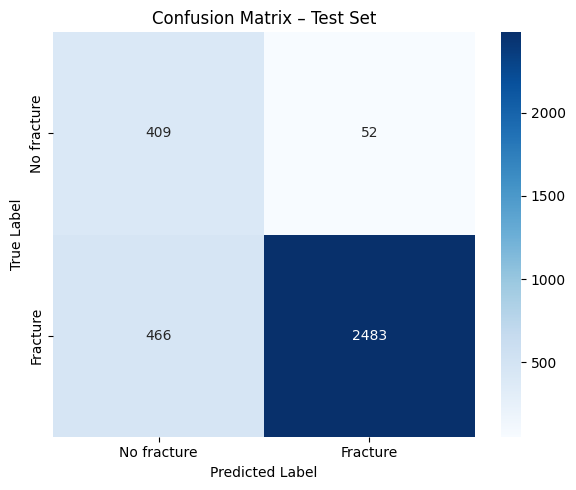

Displaying up to five correctly identified hidden fractures (out of 462 detected cases).


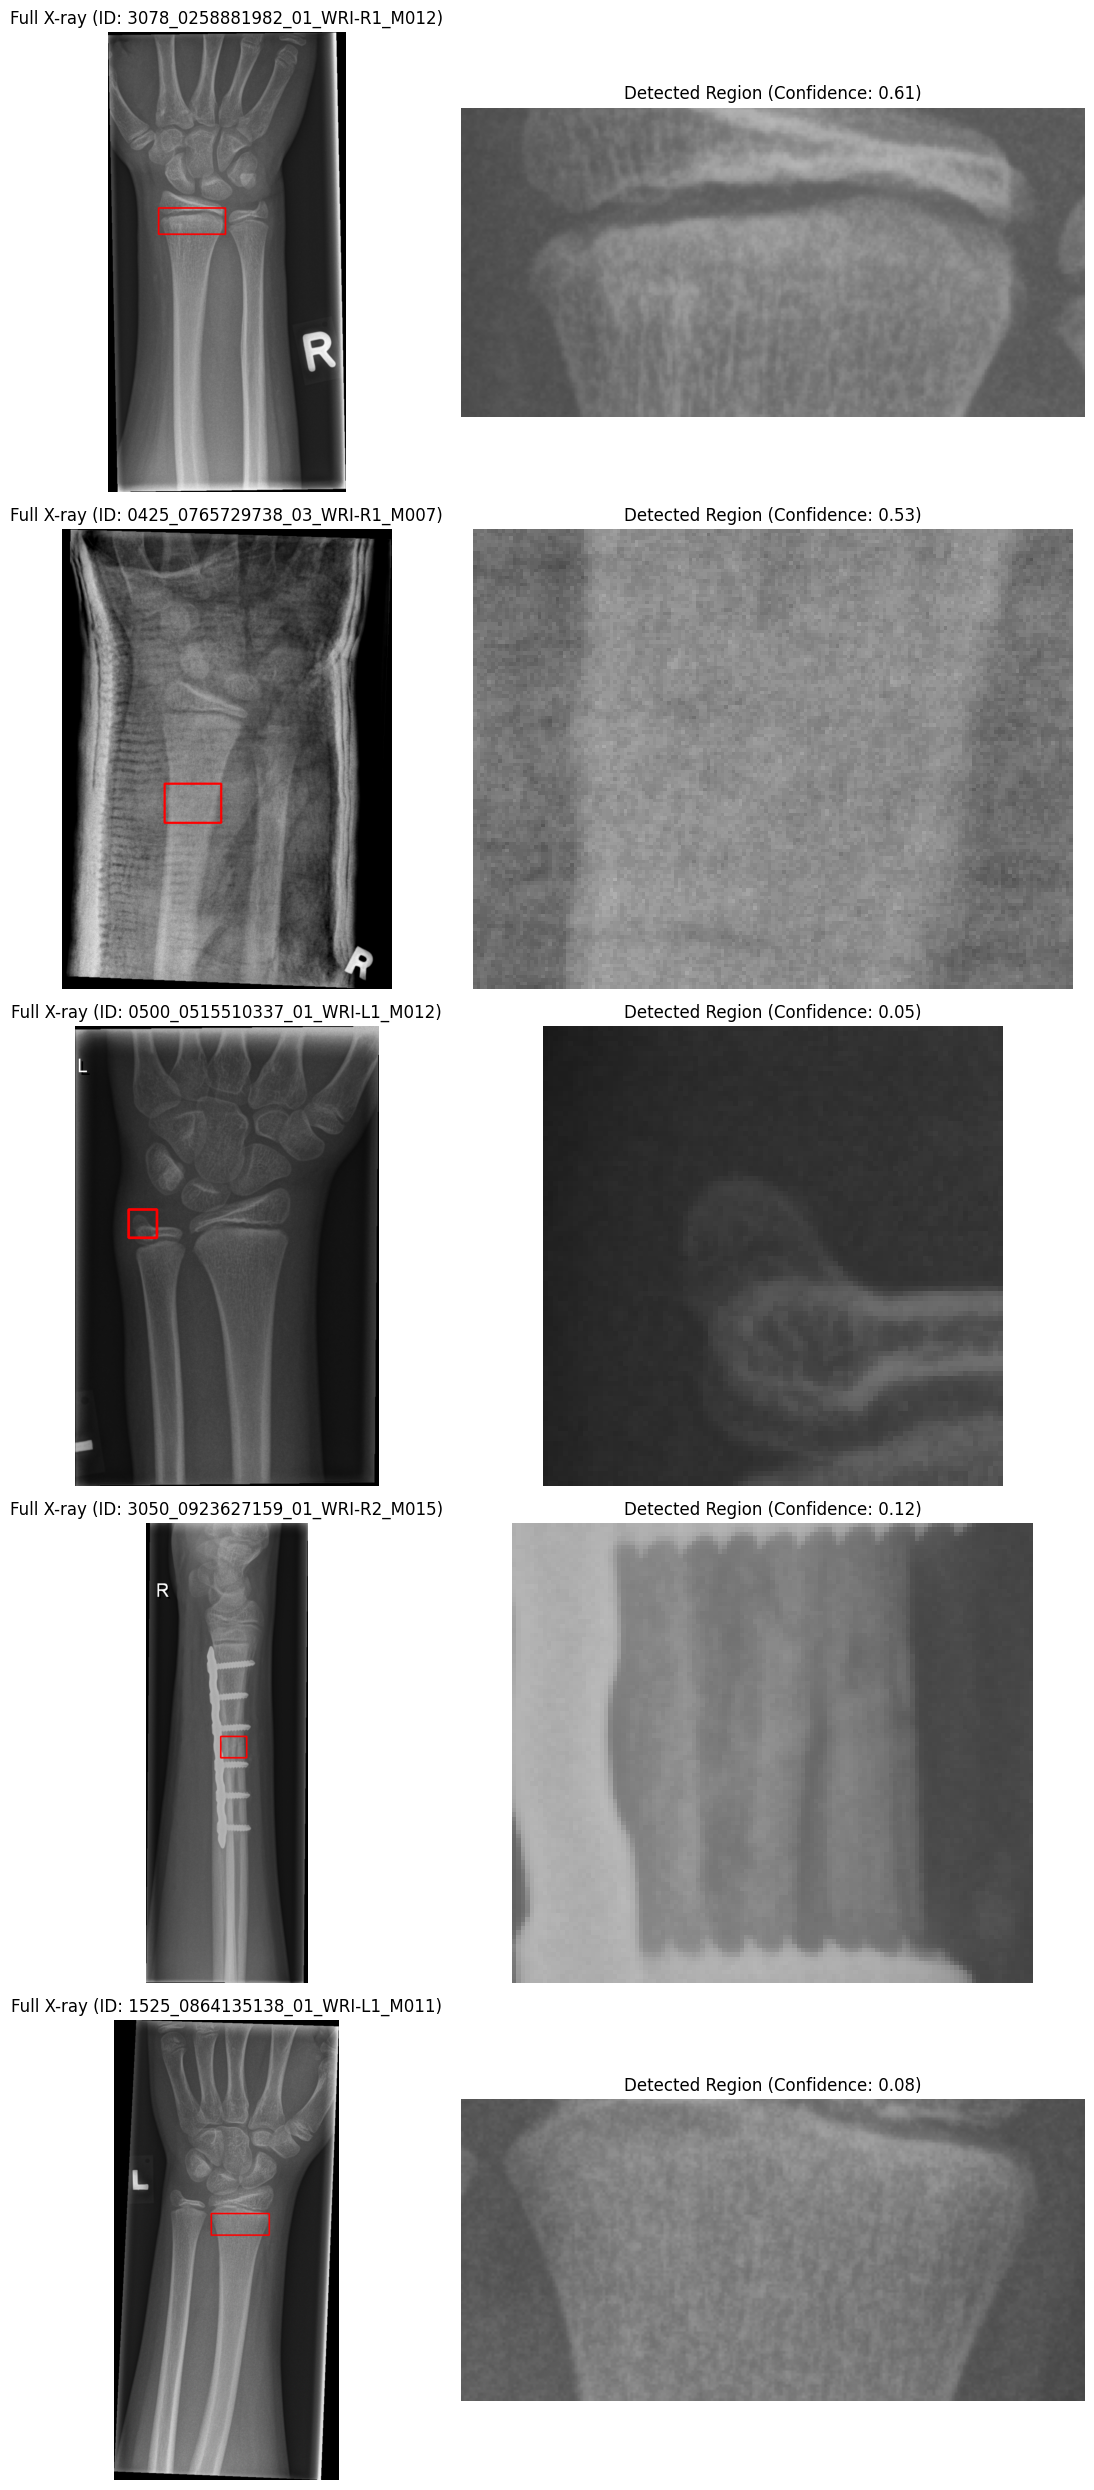

In [14]:
test_predictions = evaluate_image_classification(
    model_path=TRAINED_MODEL_PATH,
    test_csv_path=TEST_CSV_PATH
)

### 9. Inspect Another Projection of a Hidden-Fracture Case

The following example displays another X-ray projection belonging to a patient with a hidden fracture. The original YOLO annotation is used to draw the ground-truth bounding box.

This qualitative inspection helps assess whether the detected region corresponds to the fracture location across different projections.

Replace IMAGE_ID with the identifier of another image if needed.

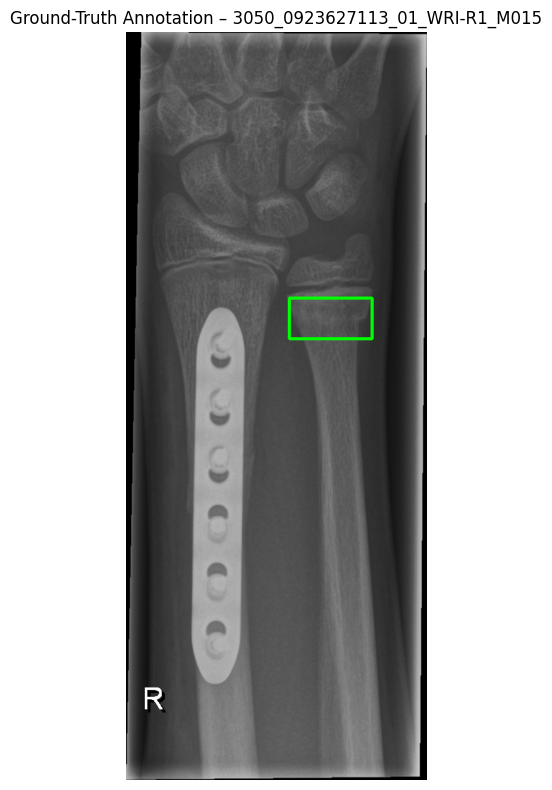

In [15]:
IMAGE_ID = "3050_0923627113_01_WRI-R1_M015"

image_path = os.path.join(TEST_IMAGE_DIR, f"{IMAGE_ID}.png")
label_path = os.path.join(
    DATASET_DIR, "labels", "test", f"{IMAGE_ID}.txt"
)

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

height, width = image.shape[:2]

# Read YOLO annotations and draw the ground-truth bounding boxes
if os.path.exists(label_path):
    with open(label_path, "r", encoding="utf-8") as file:
        for line in file:
            class_id, x_center, y_center, box_width, box_height = map(
                float, line.strip().split()
            )

            # Convert normalized YOLO coordinates to pixel coordinates
            x_min = int((x_center - box_width / 2) * width)
            y_min = int((y_center - box_height / 2) * height)
            x_max = int((x_center + box_width / 2) * width)
            y_max = int((y_center + box_height / 2) * height)

            cv2.rectangle(
                image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                3
            )
else:
    print(f"Annotation file not found: {label_path}")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Ground-Truth Annotation – {IMAGE_ID}")
plt.axis("off")
plt.tight_layout()
plt.show()

### 10. Notes on Qualitative Inspection
In the original experiment, additional projections from selected patients were inspected to assess whether the model detected the fracture region consistently across views.

In one inspected example, YOLO correctly predicted the presence of a fracture but did not localize it precisely. Other projections of the same cases were reviewed separately and included in the project presentation.